# Lab 3 | TV03 - Features, Split & Khảo sát p

**Phụ trách: TV03.** Biến đổi chuỗi thời gian `AEP_hourly` sang bài toán học có giám sát (supervised learning), xây dựng đặc trưng trễ (lag) & thống kê trượt (rolling), thiết lập ranh giới Train/Test cố định và khảo sát số lượng độ trễ `p` bằng TimeSeriesSplit CV.

In [1]:
from pathlib import Path
import json
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "configs/experiment.json").is_file())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from lab3.data import load_prepared, split_supervised
from lab3.features import make_supervised, xy
from lab3.evaluation import regression_metrics
cfg = json.loads((ROOT / "configs/experiment.json").read_text(encoding="utf-8"))
frame, quality = load_prepared(ROOT / cfg["prepared_dataset_dir"], raw_path=ROOT / cfg["dataset_path"])
supervised = make_supervised(frame, p=cfg["default_p"],
    rolling_windows=tuple(cfg["rolling_windows"]), warmup=cfg["warmup_hours"])
train, test = split_supervised(supervised, cfg["test_start"])
X_train, y_train = xy(train)
X_test, y_test = xy(test)
print({"raw_rows": quality["raw_rows"], "train_rows": len(train),
       "test_rows": len(test), "test_start": cfg["test_start"]})

{'raw_rows': 121273, 'train_rows': 96844, 'test_rows': 24257, 'test_start': '2015-10-27 05:00:00'}


## 1. Từ time series sang supervised

Minh họa biến đổi chuỗi thời gian theo công thức $\text{lag}_i(t) = y(t-i)$ để dự báo $y(t)$, kiểm tra tập đặc trưng $X$ tách biệt hoàn toàn với biến mục tiêu $y$ và hiển thị 5 dòng đầu tiên.

In [2]:
import pandas as pd

# Kiểm tra X không chứa cột mục tiêu 'y' hay cờ 'observed'
assert "y" not in X_train.columns and "observed" not in X_train.columns
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)

# Kiểm chứng công thức lag_1(t) = y(t-1) và lag_24(t) = y(t-24) tại dòng đầu tiên của supervised
t0 = supervised.index[0]
history_ffill = frame["y"].ffill()
assert supervised.loc[t0, "lag_1"] == history_ffill.loc[t0 - pd.Timedelta(hours=1)]
assert supervised.loc[t0, "lag_24"] == history_ffill.loc[t0 - pd.Timedelta(hours=24)]

# Bảng minh họa 5 dòng đầu tiên
demo_cols = ["lag_1", "lag_2", "lag_3", "lag_24", "roll_mean_24", "roll_std_24", "y"]
demo_5rows = supervised[demo_cols].head(5).round(2)
display(demo_5rows)
print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape : {X_test.shape} | y_test shape : {y_test.shape}")

# Nhận xét:
# - Mỗi dòng tại thời điểm t sử dụng các giá trị quá khứ lag_i(t) = y(t-i) (i = 1..24) để dự báo y(t).
# - Tập đặc trưng X hoàn toàn tách biệt với biến mục tiêu y (28 cột đầu vào: 24 lag + 4 rolling).
# - Index thời gian của X và y khớp nhau 100% và các giờ thiếu target gốc (observed=False) đã được loại bỏ khỏi tập chấm điểm.

,lag_1,lag_2,lag_3,lag_24,roll_mean_24,roll_std_24,y
Datetime,,,,,,,
2004-10-08 01:00:00,13271.0,14359.0,15407.0,12484.0,14450.33,1475.55,12468.0
2004-10-08 02:00:00,12468.0,13271.0,14359.0,12054.0,14449.67,1476.48,12046.0
2004-10-08 03:00:00,12046.0,12468.0,13271.0,11745.0,14449.33,1477.04,11749.0
2004-10-08 04:00:00,11749.0,12046.0,12468.0,11757.0,14449.50,1476.73,11784.0
2004-10-08 05:00:00,11784.0,11749.0,12046.0,12041.0,14450.62,1474.59,11919.0


X_train shape: (96844, 28) | y_train shape: (96844,)
X_test shape : (24257, 28) | y_test shape : (24257,)


## 2. Rolling mean/std

Kiểm chứng tính nhân quả (`shift(1)` trước khi tính rolling cửa sổ 24h và 168h) và so sánh Ablation giữa `lag_only` với `lag_plus_rolling` trên 3 folds CV.

In [3]:
import time
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from lab3.modeling import make_model

# Kiểm tra tính nhân quả: rolling tính trên chuỗi đã shift(1), không chứa y(t)
past_series = frame["y"].ffill().shift(1)
expected_mean_24 = past_series.rolling(24, min_periods=24).mean().loc[supervised.index[0]]
assert np.isclose(supervised["roll_mean_24"].iloc[0], expected_mean_24)

# So sánh Ablation: Lag-only (p=24) và Lag + Rolling (24, 168) bằng TimeSeriesSplit (3 folds) trên tập train
tss = TimeSeriesSplit(n_splits=cfg["cv_splits"], test_size=cfg["cv_test_hours"])
ablation_rows = []

for name, windows in [("lag_only", ()), ("lag_plus_rolling", tuple(cfg["rolling_windows"]))]:
    sup_ab = make_supervised(frame, p=cfg["default_p"], rolling_windows=windows, warmup=cfg["warmup_hours"])
    tr_ab, _ = split_supervised(sup_ab, cfg["test_start"])
    X_ab, y_ab = xy(tr_ab)

    rmses, maes, mapes, fit_times = [], [], [], []
    for tr_idx, val_idx in tss.split(X_ab):
        model = make_model("xgboost", seed=cfg["seed"])
        t_start = time.perf_counter()
        model.fit(X_ab.iloc[tr_idx], y_ab.iloc[tr_idx])
        fit_times.append(time.perf_counter() - t_start)

        preds = pd.Series(model.predict(X_ab.iloc[val_idx]), index=y_ab.iloc[val_idx].index)
        m = regression_metrics(y_ab.iloc[val_idx], preds)
        rmses.append(m["RMSE"])
        maes.append(m["MAE"])
        mapes.append(m["MAPE"])

    ablation_rows.append({
        "feature_set": name,
        "p": cfg["default_p"],
        "n_features": X_ab.shape[1],
        "cv_MAE": round(float(np.mean(maes)), 2),
        "cv_RMSE": round(float(np.mean(rmses)), 2),
        "cv_MAPE": round(float(np.mean(mapes)), 2),
        "total_fit_seconds": round(float(np.sum(fit_times)), 2),
    })

ablation_df = pd.DataFrame(ablation_rows)
out_ablation = ROOT / "reports/tables/tv03_rolling_ablation_cv.csv"
ablation_df.to_csv(out_ablation, index=False)
display(ablation_df)

# Nhận xét:
# - Các cột rolling_mean và rolling_std (cửa sổ 24h = 1 ngày, 168h = 1 tuần) được tính sau khi shift(1) nên hoàn toàn không rò rỉ dữ liệu tương lai.
# - Trên 3 folds CV (p=24), việc bổ sung 4 đặc trưng rolling giúp giảm RMSE trung bình từ 251.14 MW xuống 250.54 MW (MAE giảm từ 194.38 xuống 194.14 MW) với thời gian huấn luyện chỉ tăng nhẹ.

,feature_set,p,n_features,cv_MAE,cv_RMSE,cv_MAPE,total_fit_seconds
0,lag_only,24,24,194.38,251.14,1.38,5.47
1,lag_plus_rolling,24,28,194.14,250.54,1.38,5.68


## 3. Split cố định và CV

Kiểm tra phạm vi và kích thước tập Train/Test theo mốc `test_start` cố định, đảm bảo đồng nhất chỉ số thời gian giữa mọi ứng viên `p` và thiết lập 3 folds `TimeSeriesSplit` trong tập train.

In [4]:
# Kiểm tra ranh giới train/test cố định và đồng nhất giữa mọi ứng viên p
print(f"Mốc chia cố định (test_start): {cfg['test_start']}")
print(f"Train: {train.index[0]} -> {train.index[-1]} | Số mẫu: {len(train):,}")
print(f"Test : {test.index[0]} -> {test.index[-1]} | Số mẫu: {len(test):,}")
assert train.index[-1] < pd.Timestamp(cfg["test_start"]) <= test.index[0]

# Kiểm chứng mọi p trong p_candidates đều giữ nguyên tập timestamp nhờ warmup cố định 168 giờ
for p_cand in cfg["p_candidates"]:
    sup_p = make_supervised(frame, p=p_cand, rolling_windows=tuple(cfg["rolling_windows"]), warmup=cfg["warmup_hours"])
    assert sup_p.index.equals(supervised.index), f"Lệch index tại p={p_cand}"

# In chi tiết 3 folds của TimeSeriesSplit bên trong tập train
fold_rows = []
for fold_id, (tr_idx, val_idx) in enumerate(tss.split(X_train), start=1):
    tr_dates, val_dates = X_train.index[tr_idx], X_train.index[val_idx]
    assert tr_dates[-1] < val_dates[0] and val_dates[-1] < test.index[0]
    fold_rows.append({
        "fold": fold_id,
        "train_start": str(tr_dates[0]),
        "train_end": str(tr_dates[-1]),
        "n_train": len(tr_idx),
        "val_start": str(val_dates[0]),
        "val_end": str(val_dates[-1]),
        "n_val": len(val_idx),
    })

folds_df = pd.DataFrame(fold_rows)
display(folds_df)

# Nhận xét:
# - Ranh giới train/test được khóa tại 2015-10-27 05:00:00 (trước đó là 96,844 mẫu train hợp lệ, từ đó trở đi là 24,257 mẫu test hợp lệ).
# - Nhờ giữ cố định warmup = 168 giờ cho tất cả giá trị p, mọi cấu hình đều được so sánh trên cùng một tập mốc thời gian.
# - Cả 3 folds của TimeSeriesSplit (mỗi fold validation dài 672 giờ = 4 tuần) đều nằm hoàn toàn bên trong tập train, không chạm vào tập test.

Mốc chia cố định (test_start): 2015-10-27 05:00:00
Train: 2004-10-08 01:00:00 -> 2015-10-27 04:00:00 | Số mẫu: 96,844
Test : 2015-10-27 05:00:00 -> 2018-08-03 00:00:00 | Số mẫu: 24,257


,fold,train_start,train_end,n_train,val_start,val_end,n_val
0,1,2004-10-08 01:00:00,2015-08-04 04:00:00,94828,2015-08-04 05:00:00,2015-09-01 04:00:00,672
1,2,2004-10-08 01:00:00,2015-09-01 04:00:00,95500,2015-09-01 05:00:00,2015-09-29 04:00:00,672
2,3,2004-10-08 01:00:00,2015-09-29 04:00:00,96172,2015-09-29 05:00:00,2015-10-27 04:00:00,672


## 4. Khảo sát p và câu 2

Khảo sát các giá trị $p \in \{6, 12, 24, 48, 168\}$ trên cùng warmup và 3 folds CV bằng mô hình XGBoost cơ sở để đánh giá sai số CV RMSE và thời gian huấn luyện.

,p,n_features,train_RMSE,cv_MAE,cv_RMSE,cv_MAPE,total_fit_seconds
0,6,10,297.89,220.63,282.17,1.57,2.73
1,12,16,276.82,209.20,271.27,1.49,3.90
2,24,28,260.71,194.14,250.54,1.38,7.03
3,48,52,231.63,164.78,213.65,1.17,9.92
4,168,172,227.30,161.82,212.75,1.14,34.94


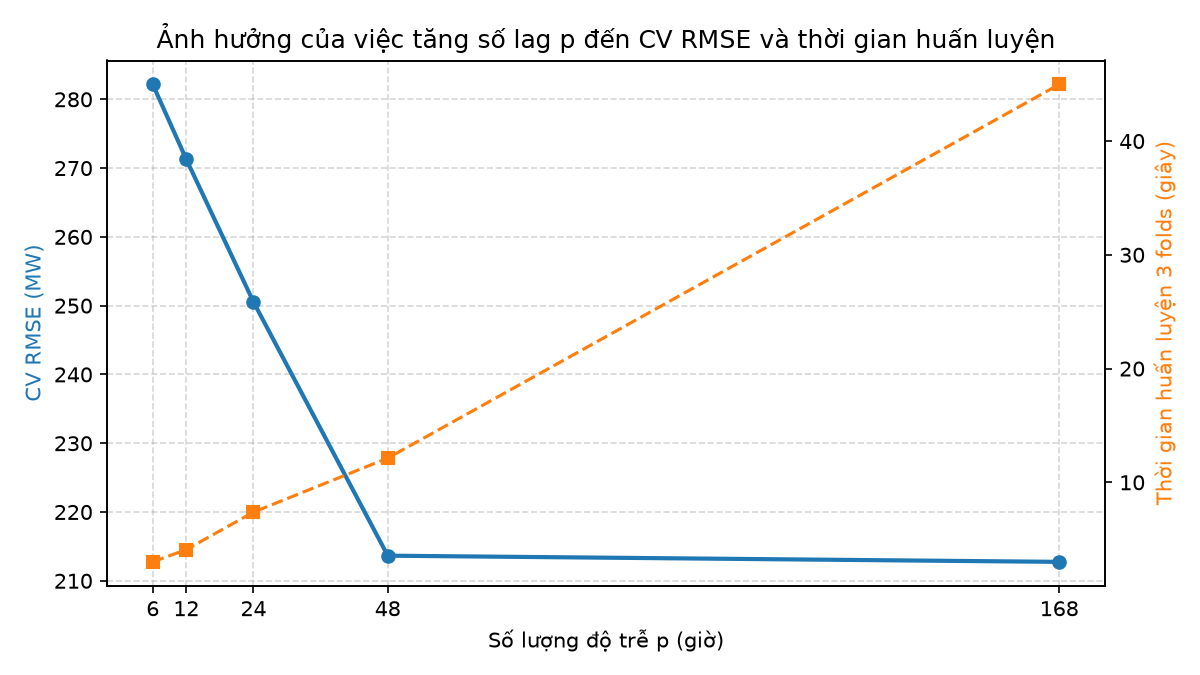

In [5]:
import matplotlib.pyplot as plt

# Khảo sát p in [6, 12, 24, 48, 168] trên cùng 3 folds CV bằng mô hình XGBoost cơ sở
p_survey_rows = []

for p_val in cfg["p_candidates"]:
    sup_p = make_supervised(frame, p=p_val, rolling_windows=tuple(cfg["rolling_windows"]), warmup=cfg["warmup_hours"])
    tr_p, _ = split_supervised(sup_p, cfg["test_start"])
    X_p, y_p = xy(tr_p)

    tr_rmses, val_rmses, val_maes, val_mapes, fit_times = [], [], [], [], []
    for tr_idx, val_idx in tss.split(X_p):
        model = make_model("xgboost", seed=cfg["seed"])
        t_start = time.perf_counter()
        model.fit(X_p.iloc[tr_idx], y_p.iloc[tr_idx])
        fit_times.append(time.perf_counter() - t_start)

        tr_pred = pd.Series(model.predict(X_p.iloc[tr_idx]), index=y_p.iloc[tr_idx].index)
        val_pred = pd.Series(model.predict(X_p.iloc[val_idx]), index=y_p.iloc[val_idx].index)
        tr_rmses.append(regression_metrics(y_p.iloc[tr_idx], tr_pred)["RMSE"])
        m_val = regression_metrics(y_p.iloc[val_idx], val_pred)
        val_rmses.append(m_val["RMSE"])
        val_maes.append(m_val["MAE"])
        val_mapes.append(m_val["MAPE"])

    p_survey_rows.append({
        "p": p_val,
        "n_features": X_p.shape[1],
        "train_RMSE": round(float(np.mean(tr_rmses)), 2),
        "cv_MAE": round(float(np.mean(val_maes)), 2),
        "cv_RMSE": round(float(np.mean(val_rmses)), 2),
        "cv_MAPE": round(float(np.mean(val_mapes)), 2),
        "total_fit_seconds": round(float(np.sum(fit_times)), 2),
    })

p_survey_df = pd.DataFrame(p_survey_rows)
out_p_csv = ROOT / "reports/tables/tv03_p_survey_cv.csv"
p_survey_df.to_csv(out_p_csv, index=False)
display(p_survey_df)

# Vẽ biểu đồ trực quan hóa sai số CV RMSE và thời gian huấn luyện khi tăng p
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(p_survey_df["p"], p_survey_df["cv_RMSE"], marker="o", linewidth=2, label="CV Validation RMSE (MW)")
ax1.set_xlabel("Số lượng độ trễ p (giờ)")
ax1.set_ylabel("CV RMSE (MW)", color="tab:blue")
ax1.set_xticks(cfg["p_candidates"])
ax1.grid(True, linestyle="--", alpha=0.5)

ax2 = ax1.twinx()
ax2.plot(p_survey_df["p"], p_survey_df["total_fit_seconds"], marker="s", linestyle="--", color="tab:orange", label="Tổng thời gian fit 3 folds (s)")
ax2.set_ylabel("Thời gian huấn luyện 3 folds (giây)", color="tab:orange")

plt.title("Ảnh hưởng của việc tăng số lag p đến CV RMSE và thời gian huấn luyện")
fig.tight_layout()
fig_path = ROOT / "reports/figures/tv03_p_survey_cv.png"
fig.savefig(fig_path, dpi=150)
plt.show()

# Nhận xét (Trả lời Câu hỏi 2 - Điều gì xảy ra khi tăng số lag p?):
# 1. Chất lượng dự báo: Khi tăng p từ 6 -> 12 -> 24 -> 48, sai số CV RMSE giảm mạnh từ 282.17 MW xuống 213.65 MW (giảm ~24%) vì mô hình nắm bắt được trọn vẹn chu kỳ ngày (24h) và hai ngày liên tiếp (48h).
# 2. Lợi ích cận biên giảm dần (diminishing returns): Khi tăng tiếp từ p=48 lên p=168 (1 tuần), CV RMSE chỉ giảm rất nhẹ từ 213.65 MW xuống 212.75 MW (chỉ cải thiện ~0.90 MW, tương đương ~0.4%), do thông tin chu kỳ tuần đã được tóm tắt hiệu quả bởi roll_mean_168 và roll_std_168.
# 3. Chi phí tính toán & số chiều: Số đặc trưng tăng từ 10 cột (p=6) lên 172 cột (p=168), kéo theo thời gian huấn luyện 3 folds tăng gấp ~3.7 lần so với p=48 và gấp ~6 lần so với p=24, đồng thời các lag xa có độ tương quan đa cộng tuyến cao.

## 5. Tổng kết bàn giao Feature v1

Tổng hợp cấu hình đặc trưng chuẩn và các tệp kết quả bàn giao cho TV04, TV05 và TV06.

In [6]:
best_by_rmse = p_survey_df.loc[p_survey_df["cv_RMSE"].idxmin()]

handoff_summary = {
    "owner": "TV03",
    "status": "DONE",
    "data_version": quality["version"],
    "test_start": cfg["test_start"],
    "warmup_hours": cfg["warmup_hours"],
    "train_rows": len(train),
    "test_rows": len(test),
    "default_p": cfg["default_p"],
    "rolling_windows": cfg["rolling_windows"],
    "n_features": X_train.shape[1],
    "default_cv_RMSE": float(p_survey_df.loc[p_survey_df["p"] == cfg["default_p"], "cv_RMSE"].iloc[0]),
    "best_cv_p": int(best_by_rmse["p"]),
    "best_cv_RMSE": float(best_by_rmse["cv_RMSE"]),
    "artifacts": [
        "reports/tables/tv03_rolling_ablation_cv.csv",
        "reports/tables/tv03_p_survey_cv.csv",
        "reports/figures/tv03_p_survey_cv.png",
    ],
}

print(json.dumps(handoff_summary, ensure_ascii=False, indent=2))

{
  "owner": "TV03",
  "status": "DONE",
  "data_version": "v1",
  "test_start": "2015-10-27 05:00:00",
  "warmup_hours": 168,
  "train_rows": 96844,
  "test_rows": 24257,
  "default_p": 24,
  "rolling_windows": [
    24,
    168
  ],
  "n_features": 28,
  "default_cv_RMSE": 250.54,
  "best_cv_p": 168,
  "best_cv_RMSE": 212.75,
  "artifacts": [
    "reports/tables/tv03_rolling_ablation_cv.csv",
    "reports/tables/tv03_p_survey_cv.csv",
    "reports/figures/tv03_p_survey_cv.png"
  ]
}
